# Calibration and rep classifier

The rules have one number that can't be known in advance: the **crease offset**, i.e. how far
below the knee joint the hip joint must be for the *surfaces* to pass the IPF depth line.
Here we (1) build a rep-level dataset, (2) do the EDA from the lightning-talk template,
(3) calibrate the offset, and (4) train classifiers to predict the human call.

> **Synthetic stand-in.** Until real labels exist, the "true" depth line is hidden at a thigh angle of
> 3° below parallel, and lifters vary in noise and body shape. Swap the dataset cell for
> `build_dataset("data/raw/squat")` merged with `data/labels.csv` once you have recordings.

In [1]:
import sys
from pathlib import Path
# make `liftjudge` importable without installing (pip install -e . also works)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from liftjudge import analyze_pose
from liftjudge.features import verdicts_to_frame
from liftjudge.rules import SquatConfig
from liftjudge.synthetic import make_squat

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

## 1. Build the dataset (one row per rep)

In [2]:
rng = np.random.default_rng(42)
TRUE_LINE_DEG = 3.0   # hidden "referee" depth line
rows = []
for i in range(300):
    lifter = f"lifter_{i % 25:02d}"
    depth_deg = rng.uniform(-12, 18)
    fault = rng.choice(["none", "none", "none", "none", "bounce", "dip", "step"])
    kw = dict(depth_deg=depth_deg, noise_px=rng.uniform(1, 4), seed=i,
              bounce=fault == "bounce", ascent_dip=0.12 if fault == "dip" else 0.0,
              step_px=45 if fault == "step" else 0.0)
    v = analyze_pose(make_squat(**kw), "squat").verdicts[0]
    r = verdicts_to_frame([v], f"video_{i:03d}").iloc[0].to_dict()
    r.update(lifter=lifter, depth_ok=int(depth_deg > TRUE_LINE_DEG))
    r["good_lift"] = int(r["depth_ok"] == 1 and fault == "none")
    rows.append(r)
reps = pd.DataFrame(rows)
reps.head()

,video_id,lift,rep,rule_status,rule_cards,squat_depth,squat_depth_status,squat_lockout_start,squat_lockout_start_status,squat_lockout_finish,...,depth_margin,descent_s,ascent_s,shoulder_drift,sticking_speed,sticking_frame,leg_conf,lifter,depth_ok,good_lift
0,video_000,squat,1,fail,blue,0.167339,pass,178.001781,pass,179.541266,...,0.167339,1.033333,0.900000,0.585769,1.362997,88,0.9,lifter_00,1,0
1,video_001,squat,1,pass,,0.089359,pass,178.277129,pass,179.952748,...,0.089359,0.700000,1.100000,0.521156,1.223515,79,0.9,lifter_01,1,1
2,video_002,squat,1,fail,blue,0.240670,pass,179.509254,pass,179.526841,...,0.240670,0.566667,1.466667,0.599566,-1.405875,78,0.9,lifter_02,1,0
3,video_003,squat,1,fail,red+blue,-0.196735,fail,177.322905,pass,179.770068,...,-0.196735,0.566667,1.500000,0.498647,-0.834034,78,0.9,lifter_03,0,0
4,video_004,squat,1,fail,red,-0.083326,fail,179.748805,pass,178.930121,...,-0.083326,0.566667,1.033333,0.490063,1.053874,79,0.9,lifter_04,0,0


## 2. EDA

In [3]:
print("Rows, columns:", reps.shape)
print("\nTarget balance (good_lift):"); print(reps.good_lift.value_counts(normalize=True).round(2))
num = reps.select_dtypes("number").columns.drop(["good_lift", "depth_ok", "rep"])
print("\nNumeric features:", len(num), "| categorical:", len(reps.columns) - len(num))
print("\nNulls:"); print(reps[num].isna().sum()[lambda s: s > 0])

Rows, columns: (300, 27)

Target balance (good_lift):
good_lift
0    0.72
1    0.28
Name: proportion, dtype: float64

Numeric features: 13 | categorical: 14

Nulls:
Series([], dtype: int64)


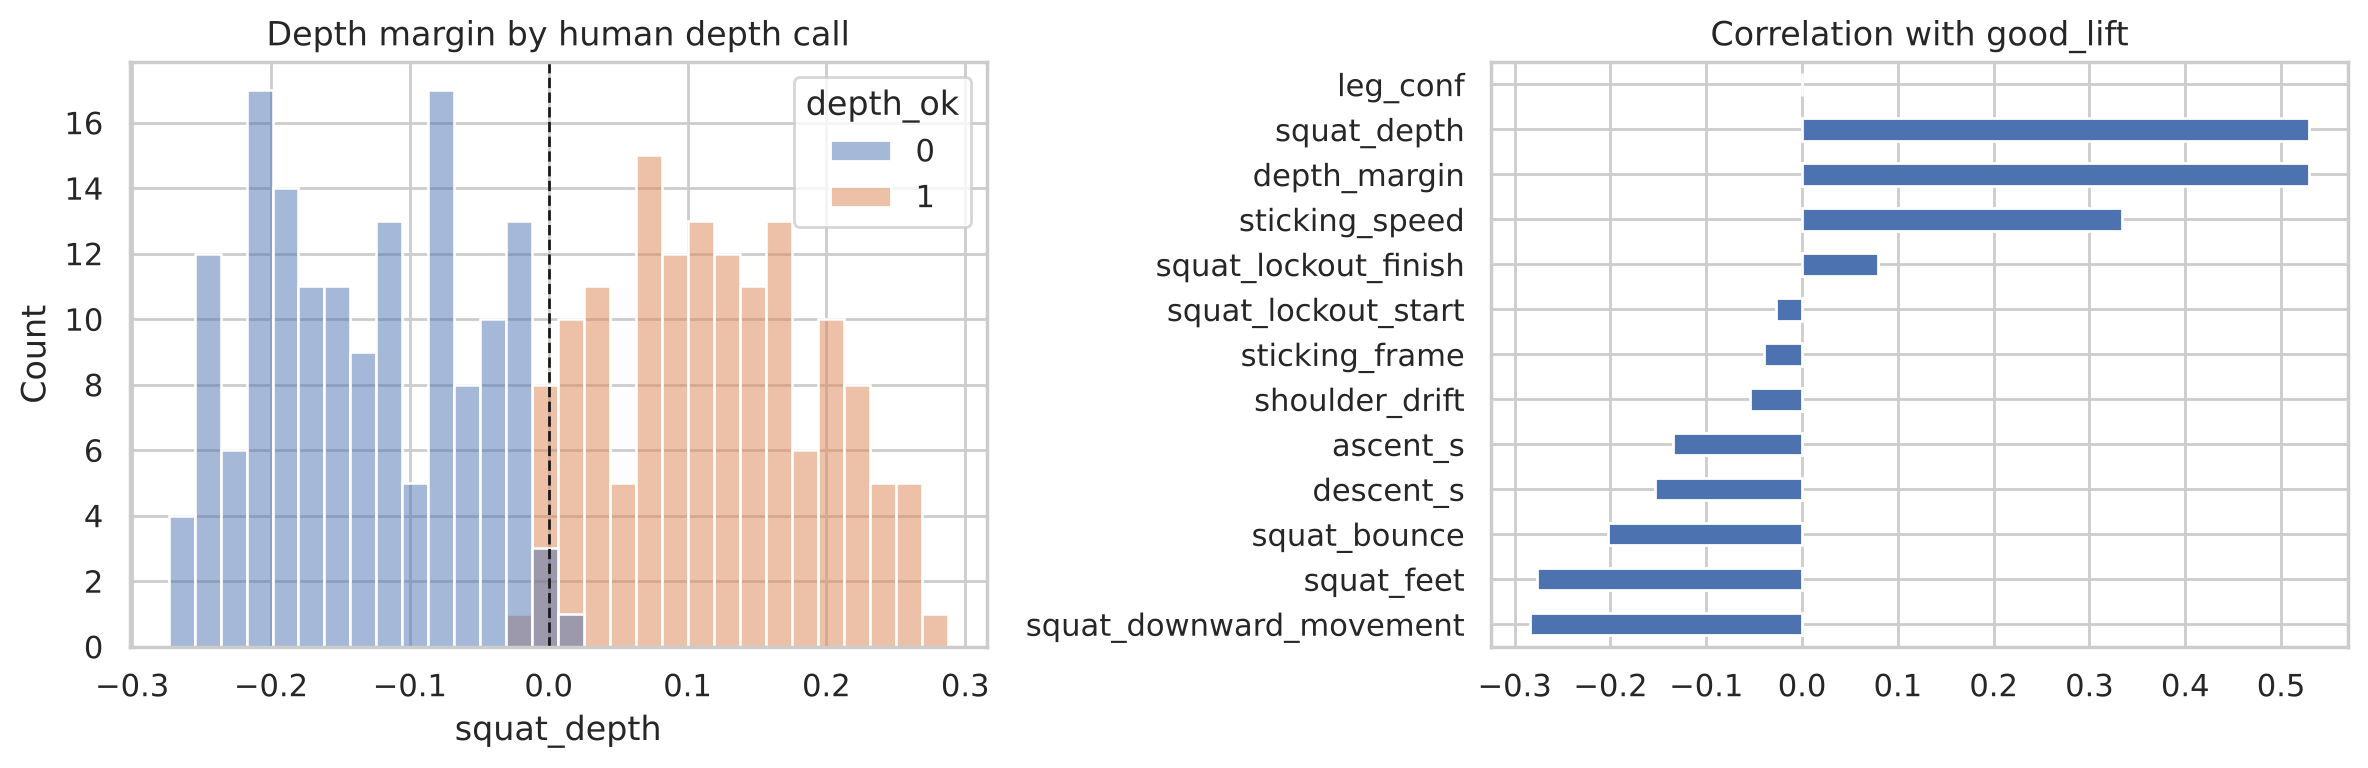

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=reps, x="squat_depth", hue="depth_ok", bins=30, ax=ax[0])
ax[0].axvline(0, color="k", ls="--", lw=1); ax[0].set_title("Depth margin by human depth call")
corr = reps[list(num) + ["good_lift"]].corr()["good_lift"].drop("good_lift").sort_values()
corr.plot.barh(ax=ax[1]); ax[1].set_title("Correlation with good_lift")
plt.tight_layout()

## 3. Calibrate the crease offset
`squat_depth` is the margin with the default offset (0.07). Sweep the offset and keep the value
that best agrees with the human depth calls; the band is then sized from the errors around it.

best crease offset: 0.062 thighs (accuracy 0.990); default was 0.07
ROC AUC of raw depth vs depth call: 0.999


Text(0.5, 1.0, 'Offset sweep')

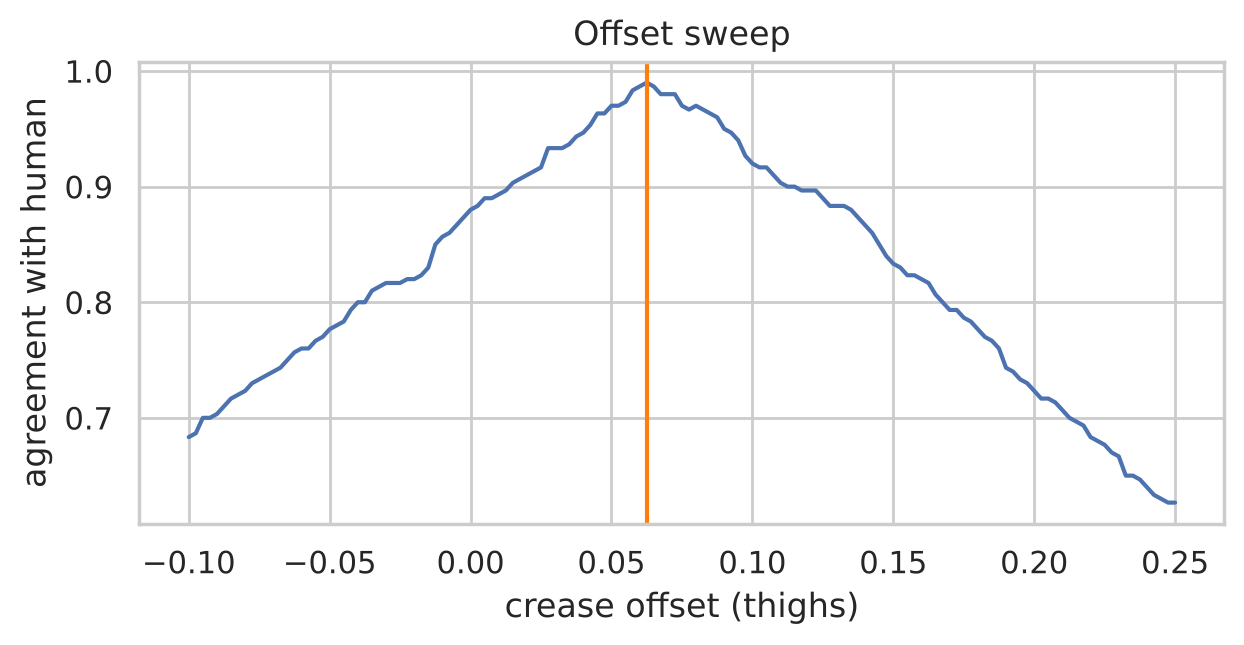

In [5]:
raw_depth = reps["squat_depth"] + SquatConfig().crease_offset   # undo the default offset
offsets = np.linspace(-0.1, 0.25, 141)
acc = [((raw_depth - o > 0).astype(int) == reps.depth_ok).mean() for o in offsets]
best = offsets[int(np.argmax(acc))]
print(f"best crease offset: {best:.3f} thighs (accuracy {max(acc):.3f}); default was {SquatConfig().crease_offset}")
print(f"ROC AUC of raw depth vs depth call: {roc_auc_score(reps.depth_ok, raw_depth):.3f}")
plt.figure(figsize=(7, 3)); plt.plot(offsets, acc); plt.axvline(best, color="tab:orange")
plt.xlabel("crease offset (thighs)"); plt.ylabel("agreement with human"); plt.title("Offset sweep")

## 4. Rep classifier: predict the human `good_lift` call
Split **by lifter** so no lifter is in both train and test. The classes are imbalanced (here most reps
are no-lifts; in real training videos it's usually the opposite), so use `class_weight="balanced"` and
focus on **recall for no-lift** (class 0): missing a bad lift is the costly mistake.

=== logistic regression
              precision    recall  f1-score   support

     no lift       1.00      0.96      0.98        71
   good lift       0.89      1.00      0.94        25

    accuracy                           0.97        96
   macro avg       0.95      0.98      0.96        96
weighted avg       0.97      0.97      0.97        96



=== random forest
              precision    recall  f1-score   support

     no lift       0.99      1.00      0.99        71
   good lift       1.00      0.96      0.98        25

    accuracy                           0.99        96
   macro avg       0.99      0.98      0.99        96
weighted avg       0.99      0.99      0.99        96

=== rules only (borderline counted as no lift)
              precision    recall  f1-score   support

     no lift       0.99      1.00      0.99        71
   good lift       1.00      0.96      0.98        25

    accuracy                           0.99        96
   macro avg       0.99      0.98      0.99        96
weighted avg       0.99      0.99      0.99        96



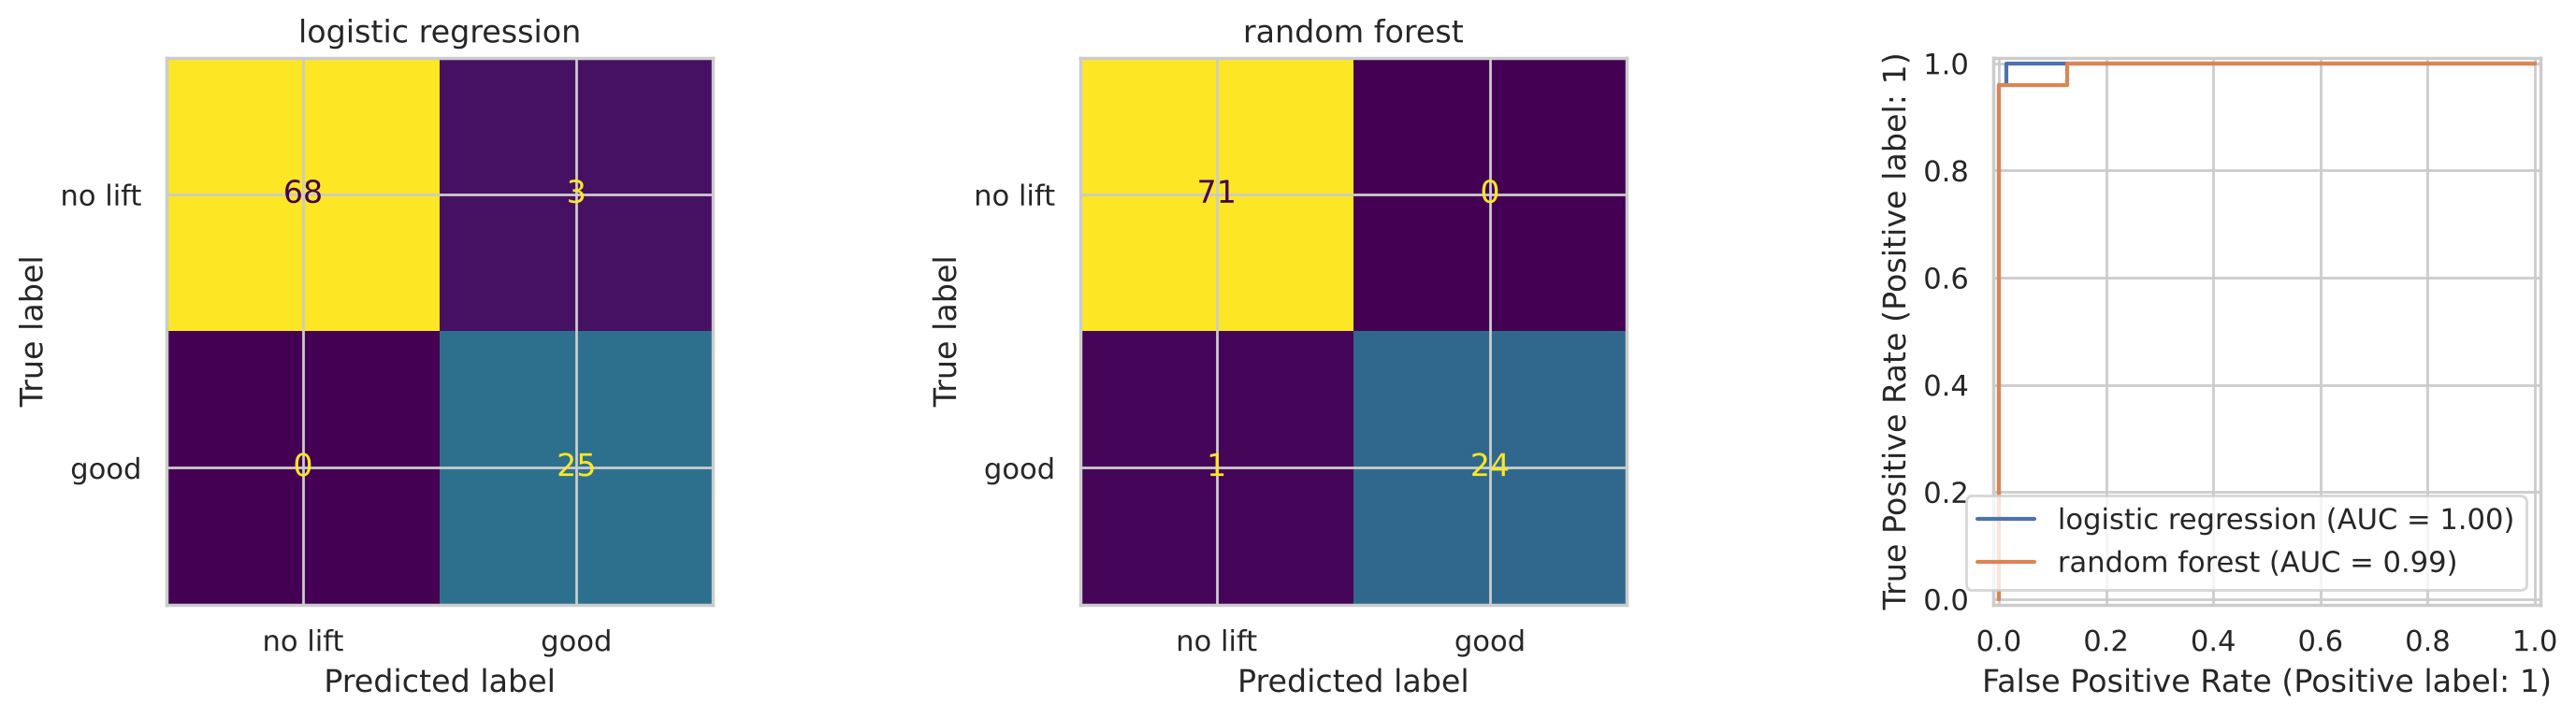

In [6]:
features = [c for c in num if not c.endswith("_frame")]
X, y, groups = reps[features].fillna(0), reps.good_lift, reps.lifter
tr, te = next(GroupShuffleSplit(test_size=0.3, random_state=0).split(X, y, groups))

models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, (name, m) in enumerate(models.items()):
    m.fit(X.iloc[tr], y.iloc[tr])
    pred = m.predict(X.iloc[te])
    print(f"=== {name}"); print(classification_report(y.iloc[te], pred, target_names=["no lift", "good lift"]))
    ConfusionMatrixDisplay.from_predictions(y.iloc[te], pred, display_labels=["no lift", "good"], ax=ax[k], colorbar=False)
    ax[k].set_title(name)
    RocCurveDisplay.from_estimator(m, X.iloc[te], y.iloc[te], ax=ax[2], name=name)
rule_pred = (reps.rule_status.iloc[te] == "pass").astype(int)
print("=== rules only (borderline counted as no lift)")
print(classification_report(y.iloc[te], rule_pred, target_names=["no lift", "good lift"]))
plt.tight_layout()

Text(0.5, 1.0, 'Random forest: most important features')

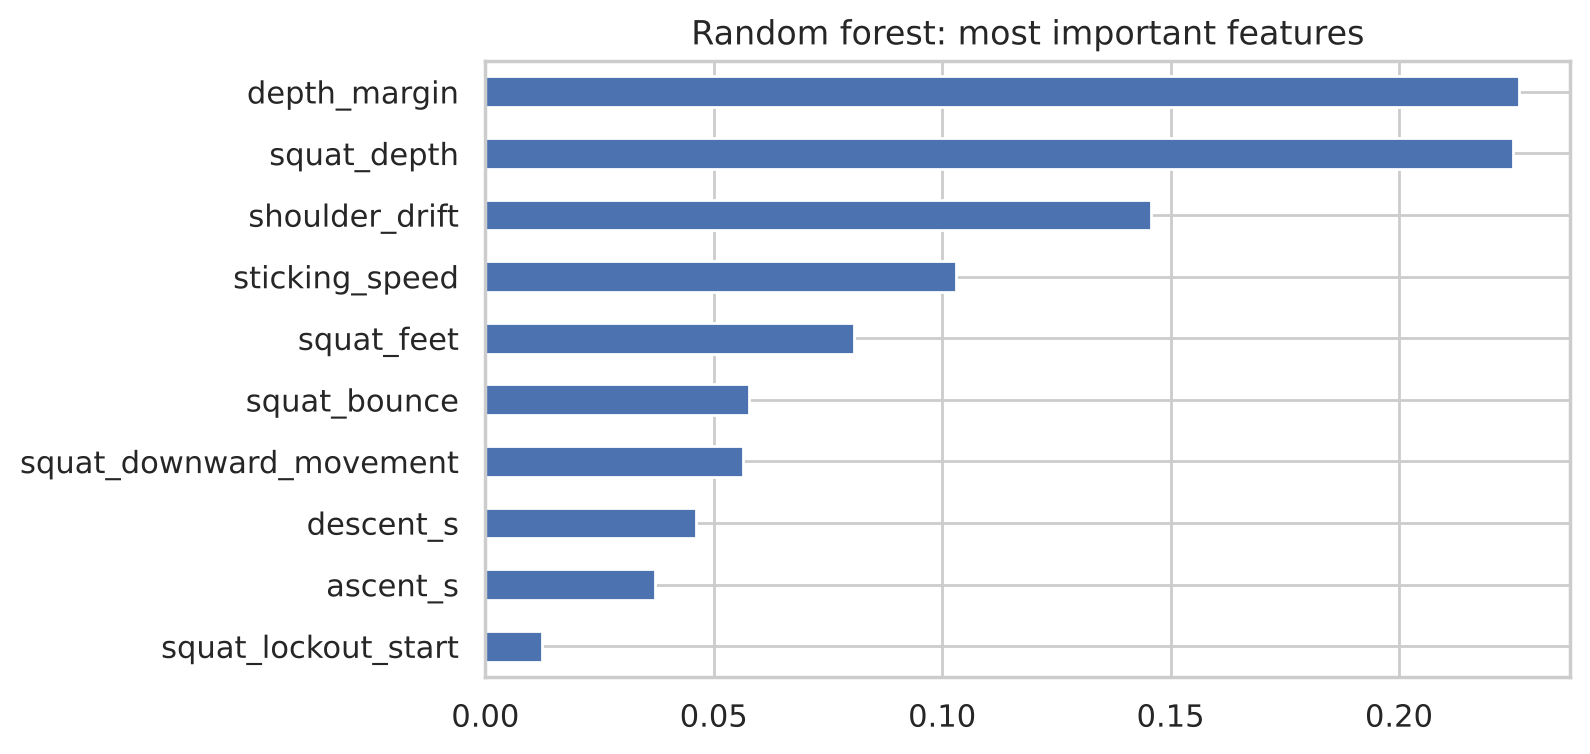

In [7]:
rf = models["random forest"]
pd.Series(rf.feature_importances_, index=features).sort_values().tail(10).plot.barh(figsize=(7, 4))
plt.title("Random forest: most important features")

## Takeaways (synthetic)
- A single calibrated offset recovers the hidden depth line, which is what we'll check on real labels.
- Rule-based checks are already explainable; the classifier is a check on whether the features carry enough
  signal and helps tune thresholds.
- On real data: compare against **two human judges** and report their agreement as the ceiling.